# Step 1 — Problem Understanding & Import Libraries

In [ ]:
# ============================================
# Adult Income Dataset
# Data Preprocessing & Feature Engineering
# ============================================

# Objective:
# Prepare the Adult Income dataset for
# Machine Learning by performing:
#
# 1. Missing Value Handling
# 2. Data Cleaning
# 3. Standard Scaling
# 4. Min-Max Scaling
# 5. Categorical Encoding
# 6. Feature Engineering
# 7. Skewness Transformation
# 8. Feature Selection / Analysis
# 9. Isolation Forest Analysis
# 10. Predictive Power Score (PPS)

In [ ]:
# ============================================
# Import Required Libraries
# ============================================

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder,
    LabelEncoder
)

# Missing Value Imputation
from sklearn.impute import SimpleImputer

# Outlier / Anomaly Detection
from sklearn.ensemble import IsolationForest

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

"What is the purpose of this project?"

Answer:

"The objective of this project was to transform a raw Adult Income dataset into a machine-learning-ready dataset by systematically handling missing values, scaling numerical features, encoding categorical variables, engineering meaningful features, transforming skewed distributions, and analyzing feature relevance and anomalies."

# Step 2 — Load Dataset & Initial Data Exploration

In [ ]:
# ============================================
#  Load the Adult Income Dataset
# ============================================

df = pd.read_csv("adult.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# Display first 5 rows

df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
# Display last 5 rows

df.tail()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
32560,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


In [ ]:
# Dataset dimensions

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 32561
Number of Columns: 15


In [ ]:
df.shape

(32561, 15)

In [ ]:
# Display all column names

df.columns.tolist()

['age',
 'workclass',
 'fnlwgt',
 'education',
 'education_num',
 'marital_status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'capital_gain',
 'capital_loss',
 'hours_per_week',
 'native_country',
 'income']

In [ ]:
df.dtypes

,0
age,int64
workclass,object
fnlwgt,int64
education,object
education_num,int64
marital_status,object
occupation,object
relationship,object
race,object
sex,object


In [ ]:
# Dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [ ]:
# Statistical summary of numerical variables

df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [ ]:
# Statistical Summary Including Categorical Variables

df.describe(include='all')

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
count,32561.000000,32561,3.256100e+04,32561,32561.000000,32561,32561,32561,32561,32561,32561.000000,32561.000000,32561.000000,32561,32561
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


For categorical variables we can see information such as:

--> number of unique values

--> most frequent value

--> frequency of most frequent value

In [ ]:
# Count missing values in each column

df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,0
sex,0


In [ ]:
# Missing-value percentage

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

missing_percentage

,0
age,0.0
workclass,0.0
fnlwgt,0.0
education,0.0
education_num,0.0
marital_status,0.0
occupation,0.0
relationship,0.0
race,0.0
sex,0.0


In [ ]:
# Check Unique Values in Categorical Columns
# First identify categorical columns:

In [ ]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include='object'
).columns

categorical_columns

Index(['workclass', 'education', 'marital_status', 'occupation',
       'relationship', 'race', 'sex', 'native_country', 'income'],
      dtype='object')

In [ ]:
# Check unique values in categorical columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].unique())


workclass
[' State-gov' ' Self-emp-not-inc' ' Private' ' Federal-gov' ' Local-gov'
 ' ?' ' Self-emp-inc' ' Without-pay' ' Never-worked']

education
[' Bachelors' ' HS-grad' ' 11th' ' Masters' ' 9th' ' Some-college'
 ' Assoc-acdm' ' Assoc-voc' ' 7th-8th' ' Doctorate' ' Prof-school'
 ' 5th-6th' ' 10th' ' 1st-4th' ' Preschool' ' 12th']

marital_status
[' Never-married' ' Married-civ-spouse' ' Divorced'
 ' Married-spouse-absent' ' Separated' ' Married-AF-spouse' ' Widowed']

occupation
[' Adm-clerical' ' Exec-managerial' ' Handlers-cleaners' ' Prof-specialty'
 ' Other-service' ' Sales' ' Craft-repair' ' Transport-moving'
 ' Farming-fishing' ' Machine-op-inspct' ' Tech-support' ' ?'
 ' Protective-serv' ' Armed-Forces' ' Priv-house-serv']

relationship
[' Not-in-family' ' Husband' ' Wife' ' Own-child' ' Unmarried'
 ' Other-relative']

race
[' White' ' Black' ' Asian-Pac-Islander' ' Amer-Indian-Eskimo' ' Other']

sex
[' Male' ' Female']

native_country
[' United-States' ' Cuba' ' Jamaica' ' 

In [ ]:
# Number of unique categories

for col in categorical_columns:
    print(
        f"{col}: {df[col].nunique()} unique categories"
    )

workclass: 9 unique categories
education: 16 unique categories
marital_status: 7 unique categories
occupation: 15 unique categories
relationship: 6 unique categories
race: 5 unique categories
sex: 2 unique categories
native_country: 42 unique categories
income: 2 unique categories


Examine the Target Variable

In [ ]:
# Target variable distribution

df['income'].value_counts()

,count
income,
<=50K,24720
>50K,7841


In [ ]:
# Target variable percentage distribution

df['income'].value_counts(normalize=True) * 100

,proportion
income,
<=50K,75.919044
>50K,24.080956


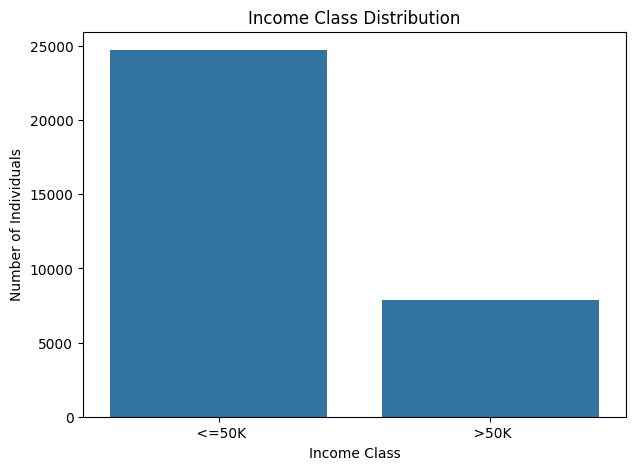

In [ ]:
# Target variable distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='income'
)

plt.title("Income Class Distribution")
plt.xlabel("Income Class")
plt.ylabel("Number of Individuals")

plt.show()

### Initial Data Exploration Summary

At this stage, we have investigated:

| Investigation             | Purpose                         |
| ------------------------- | ------------------------------- |
| `head()`                  | First look at data              |
| `tail()`                  | Verify ending records           |
| `shape`                   | Dataset size                    |
| `columns`                 | Identify variables              |
| `dtypes`                  | Identify data types             |
| `info()`                  | Structure + missingness         |
| `describe()`              | Numerical statistics            |
| `describe(include='all')` | Numerical + categorical summary |
| `isnull().sum()`          | Missing-value detection         |
| `unique()`                | Category inspection             |
| `nunique()`               | Category cardinality            |
| `value_counts()`          | Target distribution             |


"Why do you perform initial data exploration before preprocessing?"

answer:

"Initial data exploration helps identify the dataset structure, data types, missing-value patterns, categorical cardinality, target distribution, and potential data-quality issues. These observations allow me to select preprocessing techniques based on the actual characteristics of the data rather than applying transformations blindly."

# Step 3 — Data Cleaning & Missing Value Handling

In [ ]:
# ============================================
#  Data Cleaning & Missing Values
# ============================================

# Check standard missing values

df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,0
sex,0


In [ ]:
# Missing value percentage

missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().sum() / len(df) * 100
    )
})

missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Count,Missing Percentage
age,0,0.0
workclass,0,0.0
fnlwgt,0,0.0
education,0,0.0
education_num,0,0.0
marital_status,0,0.0
occupation,0,0.0
relationship,0,0.0
race,0,0.0
sex,0,0.0


In [ ]:
# Show unique values from each column that contain ?
for col in df.columns:
    values_with_q = df[col].astype(str)[df[col].astype(str).str.contains(r'\?', regex=True, na=False)]

    if len(values_with_q) > 0:
        print(f"\n{col}:")
        print(values_with_q.value_counts())


workclass:
workclass
?    1836
Name: count, dtype: int64

occupation:
occupation
?    1843
Name: count, dtype: int64

native_country:
native_country
?    583
Name: count, dtype: int64


In [ ]:
question_mark_count = (
    df.astype(str)
      .apply(lambda col: col.str.strip().eq('?').sum())
      .sort_values(ascending=False)
)

question_mark_count

,0
occupation,1843
workclass,1836
native_country,583
fnlwgt,0
education,0
education_num,0
age,0
marital_status,0
relationship,0
sex,0


In [ ]:
missing_values = ['?', 'NA', 'N/A', 'na', 'null', 'None', '']

missing_count = (
    df.astype(str)
      .apply(lambda col: col.str.strip().isin(missing_values).sum())
      .sort_values(ascending=False)
)

missing_count

,0
occupation,1843
workclass,1836
native_country,583
fnlwgt,0
education,0
education_num,0
age,0
marital_status,0
relationship,0
sex,0


In [ ]:
# Count '?' values in each column

# question_mark_count = (
#     df.astype(str)
#       .apply(lambda col: (col == '?').sum())
#       .sort_values(ascending=False)
# )

# question_mark_count

In [ ]:
# Replace '?' with NaN

#df = df.replace('?', np.nan)

In [ ]:
# Replace '?' values with NaN, even if surrounded by whitespace
df = df.replace(r'^\s*\?\s*$', np.nan, regex=True)

In [ ]:
# Check missing values after replacement

df.isnull().sum().sort_values(
    ascending=False
)

,0
occupation,1843
workclass,1836
native_country,583
fnlwgt,0
education,0
education_num,0
age,0
marital_status,0
relationship,0
sex,0


In [ ]:
# Updated missing-value summary

missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().sum() / len(df) * 100
    )
})

missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values(
    by='Missing Percentage',
    ascending=False
)

missing_summary

,Missing Count,Missing Percentage
occupation,1843,5.660146
workclass,1836,5.638647
native_country,583,1.790486


In [ ]:
# Identify numerical columns

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

Numerical Columns:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']


In [ ]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include='object'
).columns

print("Categorical Columns:")
print(categorical_columns.tolist())

Categorical Columns:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


In [ ]:
# Numerical columns with missing values

numerical_missing = [
    col for col in numerical_columns
    if df[col].isnull().sum() > 0
]

# Categorical columns with missing values

categorical_missing = [
    col for col in categorical_columns
    if df[col].isnull().sum() > 0
]

print("Numerical columns with missing values:")
print(numerical_missing)

print("\nCategorical columns with missing values:")
print(categorical_missing)

Numerical columns with missing values:
[]

Categorical columns with missing values:
['workclass', 'occupation', 'native_country']


In [ ]:
# Median Imputation for Numerical Variables

numerical_imputer = SimpleImputer(
    strategy='median'
)

df[numerical_columns] = numerical_imputer.fit_transform(
    df[numerical_columns]
)

In [ ]:
# Mode Imputation for Categorical Variables

categorical_imputer = SimpleImputer(
    strategy='most_frequent'
)

df[categorical_columns] = categorical_imputer.fit_transform(
    df[categorical_columns]
)

In [ ]:
# Verify remaining missing values

df.isnull().sum().sort_values(
    ascending=False
)

,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,0
sex,0


In [ ]:
# Verify that '?' values are removed

question_mark_count = (
    df.astype(str)
      .apply(lambda col: (col == '?').sum())
      .sum()
)

print("Remaining '?' values:", question_mark_count)

Remaining '?' values: 0


In [ ]:
print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (32561, 15)


In [ ]:
# Final data quality check

print("Missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDataset shape:")
print(df.shape)

Missing values:
0

Duplicate rows:
24

Dataset shape:
(32561, 15)


"How did you handle missing values in the Adult Income dataset?"

answer:

"I first checked both standard null values and the dataset-specific ? representation. I converted ? to NaN, then used median imputation for numerical variables because it is robust to outliers and mode imputation for categorical variables. Finally, I validated that no unintended missing values remained."

# Step 4 — Numerical Feature Analysis

In [ ]:
# ============================================
#  Numerical Feature Analysis
# ============================================

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical Features:")
print(numerical_columns.tolist())

Numerical Features:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']


In [ ]:
# Descriptive statistics

df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [ ]:
# Calculate skewness

skewness = (
    df[numerical_columns]
    .skew()
    .sort_values(ascending=False)
)

skewness

,0
capital_gain,11.953848
capital_loss,4.594629
fnlwgt,1.446980
age,0.558743
hours_per_week,0.227643
education_num,-0.311676


How to Interpret Skewness

A useful rule of thumb:

|   Skewness | Interpretation           |
| ---------: | ------------------------ |
|   Around 0 | Approximately symmetric  |
|   0 to 0.5 | Slight positive skew     |
|   0.5 to 1 | Moderate positive skew   |
|        > 1 | Highly positively skewed |
|  -0.5 to 0 | Slight negative skew     |
| -1 to -0.5 | Moderate negative skew   |
|       < -1 | Highly negatively skewed |


In [ ]:
# Identify highly skewed numerical features

highly_skewed_features = skewness[
    skewness.abs() > 1
]

highly_skewed_features

,0
capital_gain,11.953848
capital_loss,4.594629
fnlwgt,1.446980


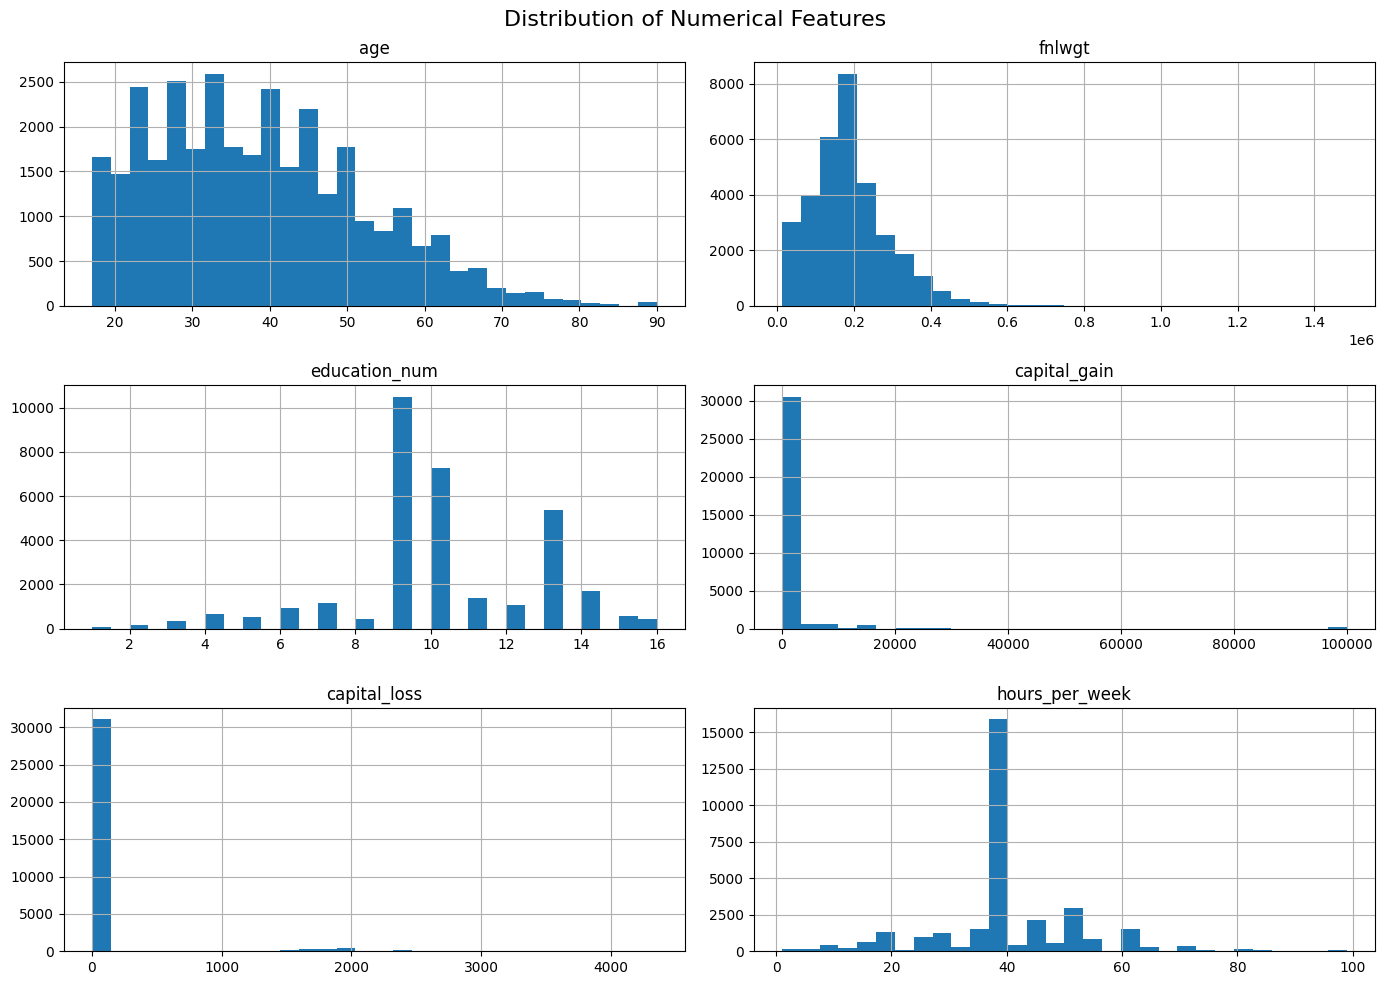

In [ ]:
# Histograms for numerical features

df[numerical_columns].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

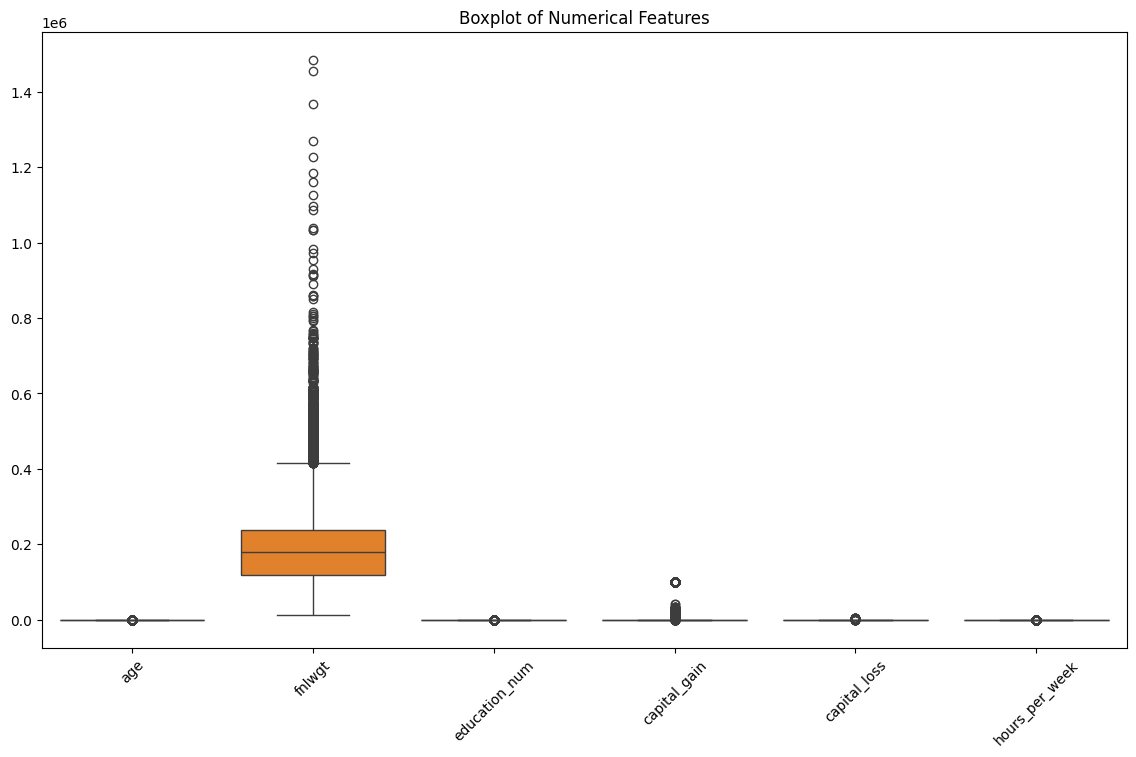

In [ ]:
# Boxplots for numerical variables

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df[numerical_columns]
)

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)

plt.show()

In [ ]:
# ============================================
# IQR Outlier Analysis
# ============================================

outlier_summary = []

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outliers,
        'Outlier %': outliers / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    by='Outlier %',
    ascending=False
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
5,hours_per_week,40.0,45.0,5.0,32.5,52.5,9008,27.664998
3,capital_gain,0.0,0.0,0.0,0.0,0.0,2712,8.328983
4,capital_loss,0.0,0.0,0.0,0.0,0.0,1519,4.665090
2,education_num,9.0,12.0,3.0,4.5,16.5,1198,3.679248
1,fnlwgt,117827.0,237051.0,119224.0,-61009.0,415887.0,992,3.046589
0,age,28.0,48.0,20.0,-2.0,78.0,143,0.439176


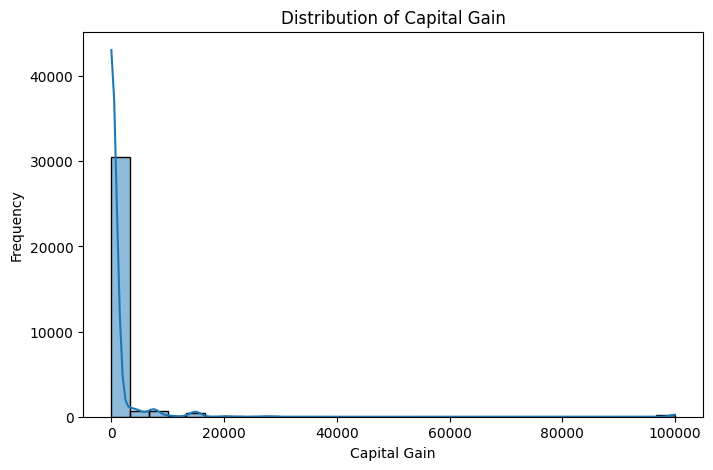

In [ ]:
# Distribution of Capital Gain

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='capital_gain',
    bins=30,
    kde=True
)

plt.title("Distribution of Capital Gain")
plt.xlabel("Capital Gain")
plt.ylabel("Frequency")

plt.show()

In [ ]:
# Log transformation of Capital Gain

df['capital_gain_log'] = np.log1p(
    df['capital_gain']
)

In [ ]:
# Compare skewness

original_skewness = df['capital_gain'].skew()
transformed_skewness = df['capital_gain_log'].skew()

print(
    "Original Capital Gain Skewness:",
    original_skewness
)

print(
    "Transformed Capital Gain Skewness:",
    transformed_skewness
)

Original Capital Gain Skewness: 11.953847687699799
Transformed Capital Gain Skewness: 3.096143524467517


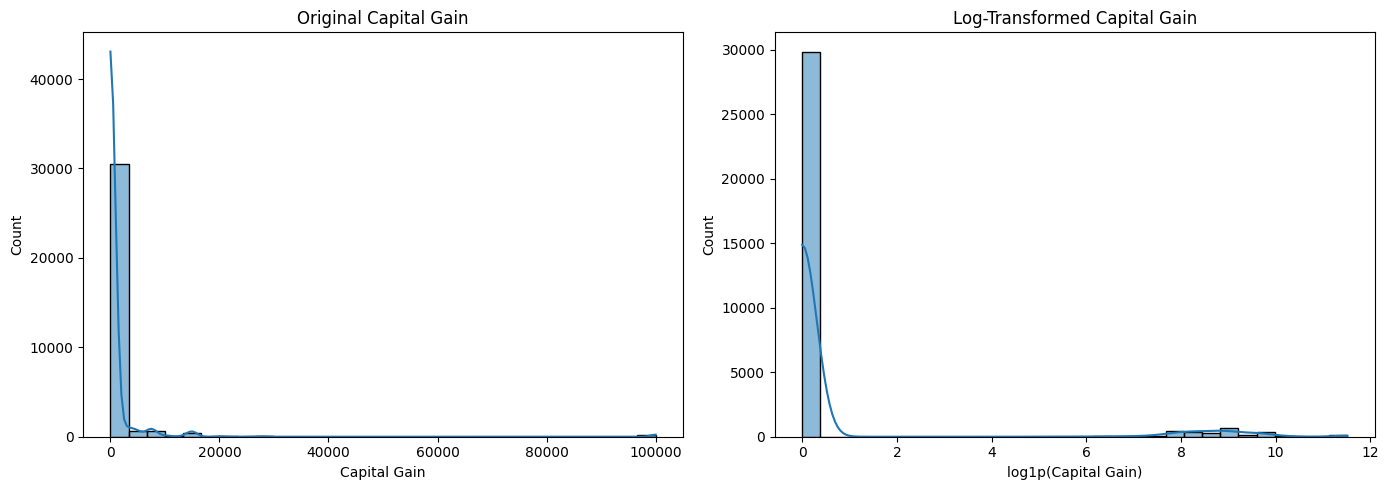

In [ ]:
# Compare original and transformed distributions

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

sns.histplot(
    df['capital_gain'],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title(
    "Original Capital Gain"
)

axes[0].set_xlabel(
    "Capital Gain"
)

sns.histplot(
    df['capital_gain_log'],
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title(
    "Log-Transformed Capital Gain"
)

axes[1].set_xlabel(
    "log1p(Capital Gain)"
)

plt.tight_layout()
plt.show()

### Why Log Transformation?

Log transformation is useful when:

-- data is strongly right-skewed

-- values span a large range

-- extreme values dominate the distribution

-- we want to reduce the influence of very large observations

In our case, capital-gain is a sensible candidate because its distribution can contain a large number of low values and a small number of very large values.

"Why did you apply log transformation to Capital Gain?"

Answer:

"Capital Gain showed substantial positive skewness with a long right tail. I used a log1p transformation because the feature contains zero values, and log1p safely handles zero while compressing extreme values and reducing skewness without removing legitimate observations."

# Step 5 — Standard Scaling

In [ ]:
# ============================================
#  Standard Scaling
# ============================================

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Remove transformed feature from this initial comparison
# because it is a derived version of capital-gain.

numerical_columns_for_scaling = [
    col for col in numerical_columns
    if col != 'capital_gain_log'
]

numerical_columns_for_scaling

['age',
 'fnlwgt',
 'education_num',
 'capital_gain',
 'capital_loss',
 'hours_per_week']

In [ ]:
# Create StandardScaler

standard_scaler = StandardScaler()

In [ ]:
# Apply Standard Scaling

df_standard_scaled = df.copy()

df_standard_scaled[
    numerical_columns_for_scaling
] = standard_scaler.fit_transform(
    df_standard_scaled[
        numerical_columns_for_scaling
    ]
)

Compare Before and After Scaling

Let's inspect the original data:

In [ ]:
df[numerical_columns_for_scaling].describe().T

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


Now inspect the standardized data:

In [ ]:
df_standard_scaled[
    numerical_columns_for_scaling
].describe().T

,count,mean,std,min,25%,50%,75%,max
age,32561.0,-2.705915e-17,1.000015,-1.582206,-0.775768,-0.115955,0.690484,3.769612
fnlwgt,32561.0,-1.001625e-16,1.000015,-1.681631,-0.681691,-0.108219,0.447877,12.268563
education_num,32561.0,1.471887e-16,1.000015,-3.529656,-0.420060,-0.031360,0.746039,2.300838
capital_gain,32561.0,1.309314e-17,1.000015,-0.145920,-0.145920,-0.145920,-0.145920,13.394578
capital_loss,32561.0,1.016900e-16,1.000015,-0.216660,-0.216660,-0.216660,-0.216660,10.593507
hours_per_week,32561.0,-1.549355e-17,1.000015,-3.194030,-0.035429,-0.035429,0.369519,4.742967


Verify Mean and Standard Deviation

In [ ]:
# Check mean after Standard Scaling

df_standard_scaled[
    numerical_columns_for_scaling
].mean()

,0
age,-2.705915e-17
fnlwgt,-1.001625e-16
education_num,1.471887e-16
capital_gain,1.309314e-17
capital_loss,1.016900e-16
hours_per_week,-1.549355e-17


In [ ]:
# Check standard deviation after Standard Scaling

df_standard_scaled[
    numerical_columns_for_scaling
].std()

,0
age,1.000015
fnlwgt,1.000015
education_num,1.000015
capital_gain,1.000015
capital_loss,1.000015
hours_per_week,1.000015


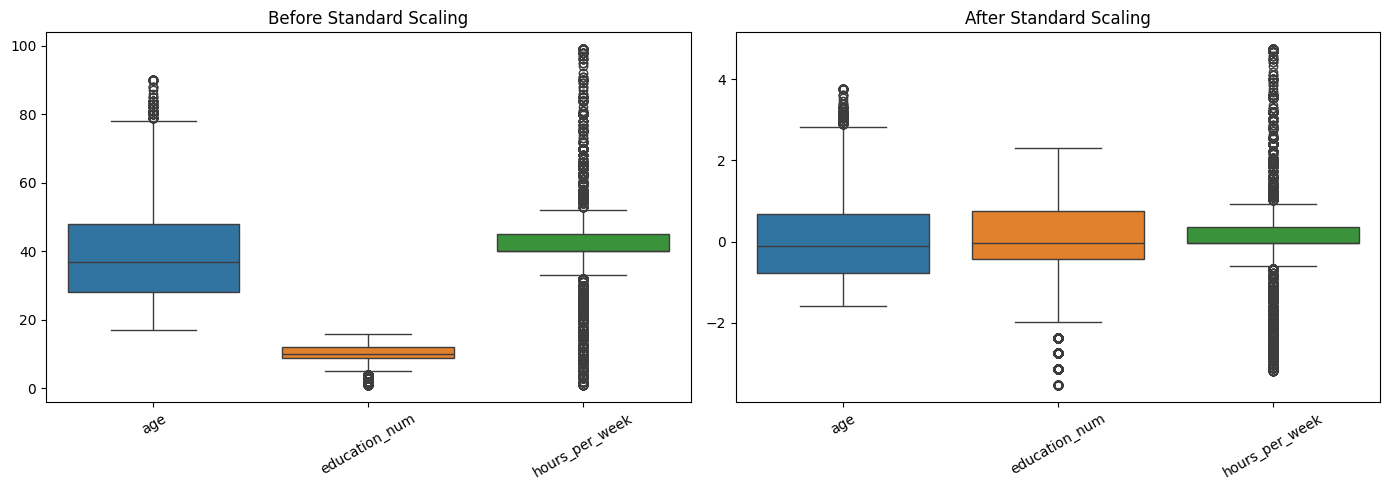

In [ ]:
# Compare distributions before and after scaling

features_to_compare = [
    'age',
    'education_num',
    'hours_per_week'
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.boxplot(
    data=df[features_to_compare],
    ax=axes[0]
)

axes[0].set_title(
    "Before Standard Scaling"
)

axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(
    data=df_standard_scaled[features_to_compare],
    ax=axes[1]
)

axes[1].set_title(
    "After Standard Scaling"
)

axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
# Manually verify Standard Scaling for age

x = df['age'].iloc[0]

mean_age = df['age'].mean()
std_age = df['age'].std()

manual_z = (
    x - mean_age
) / std_age

print("Original Age:", x)
print("Mean Age:", mean_age)
print("Standard Deviation:", std_age)
print("Manual Standardized Value:", manual_z)
print(
    "Scaler Value:",
    df_standard_scaled['age'].iloc[0]
)

Original Age: 39.0
Mean Age: 38.58164675532078
Standard Deviation: 13.640432553581146
Manual Standardized Value: 0.03067008638002341
Scaler Value: 0.030670557354391753


Important ML Practice — Fit Only on Training Data

In an actual Machine Learning project, we should not fit the scaler on the complete dataset before splitting into train and test data.

Why?

Because the scaler calculates:

Mean

Standard Deviation

If we calculate them using the entire dataset, information from the test set can indirectly influence the training process.

This is called:

**Data Leakage**

The correct ML workflow is:

Raw Data

   ↓

Train / Test Split

   ↓

Fit Scaler on Training Data

   ↓

Transform Training Data

   ↓

Transform Test Data using same scaler

StandardScaler with Train-Test Data

For demonstration, let's show the correct approach.

First separate the target.

In [ ]:
# Separate features and target

X = df.drop(
    columns=['income']
)

y = df['income']

Then

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Now identify numerical features in X_train:

In [ ]:
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns

numerical_features

Index(['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss',
       'hours_per_week', 'capital_gain_log'],
      dtype='object')

Fit the scaler only on training data:

In [ ]:
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_features] = (
    scaler.fit_transform(
        X_train[numerical_features]
    )
)

X_test_scaled[numerical_features] = (
    scaler.transform(
        X_test[numerical_features]
    )
)

Notice the difference:

Training Data:

fit_transform()

Testing Data:

transform()

This is the correct Machine Learning practice.

### "Why did you use StandardScaler?"

answer:

"The numerical variables in the Adult Income dataset have substantially different ranges. I used StandardScaler to standardize the features so they are centered around zero with unit variance. This is particularly useful for scale-sensitive algorithms such as Logistic Regression, SVM, KNN, K-Means, and regularized linear models. I also ensured that in an ML setting the scaler would be fitted only on training data to prevent data leakage."

# Step 6 — Min-Max Scaling

In [ ]:
# ============================================
#  Min-Max Scaling
# ============================================

minmax_scaler = MinMaxScaler()

In [ ]:
# Create a copy for Min-Max scaling

df_minmax_scaled = df.copy()

In [ ]:
# Apply Min-Max Scaling

df_minmax_scaled[
    numerical_columns_for_scaling
] = minmax_scaler.fit_transform(
    df_minmax_scaled[
        numerical_columns_for_scaling
    ]
)

Verify Min-Max Scaling

In [ ]:
# Check minimum values

df_minmax_scaled[
    numerical_columns_for_scaling
].min()

,0
age,0.0
fnlwgt,0.0
education_num,0.0
capital_gain,0.0
capital_loss,0.0
hours_per_week,0.0


In [ ]:
# Check maximum values

df_minmax_scaled[
    numerical_columns_for_scaling
].max()

,0
age,1.0
fnlwgt,1.0
education_num,1.0
capital_gain,1.0
capital_loss,1.0
hours_per_week,1.0


In [ ]:
# Compare descriptive statistics

print("ORIGINAL DATA")
display(
    df[numerical_columns_for_scaling]
    .describe()
    .T
)

print("\nSTANDARD SCALED DATA")
display(
    df_standard_scaled[numerical_columns_for_scaling]
    .describe()
    .T
)

print("\nMIN-MAX SCALED DATA")
display(
    df_minmax_scaled[numerical_columns_for_scaling]
    .describe()
    .T
)

ORIGINAL DATA


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0



STANDARD SCALED DATA


,count,mean,std,min,25%,50%,75%,max
age,32561.0,-2.705915e-17,1.000015,-1.582206,-0.775768,-0.115955,0.690484,3.769612
fnlwgt,32561.0,-1.001625e-16,1.000015,-1.681631,-0.681691,-0.108219,0.447877,12.268563
education_num,32561.0,1.471887e-16,1.000015,-3.529656,-0.420060,-0.031360,0.746039,2.300838
capital_gain,32561.0,1.309314e-17,1.000015,-0.145920,-0.145920,-0.145920,-0.145920,13.394578
capital_loss,32561.0,1.016900e-16,1.000015,-0.216660,-0.216660,-0.216660,-0.216660,10.593507
hours_per_week,32561.0,-1.549355e-17,1.000015,-3.194030,-0.035429,-0.035429,0.369519,4.742967



MIN-MAX SCALED DATA


,count,mean,std,min,25%,50%,75%,max
age,32561.0,0.295639,0.186855,0.0,0.150685,0.273973,0.424658,1.0
fnlwgt,32561.0,0.120545,0.071685,0.0,0.071679,0.112788,0.152651,1.0
education_num,32561.0,0.605379,0.171515,0.0,0.533333,0.600000,0.733333,1.0
capital_gain,32561.0,0.010777,0.073854,0.0,0.000000,0.000000,0.000000,1.0
capital_loss,32561.0,0.020042,0.092507,0.0,0.000000,0.000000,0.000000,1.0
hours_per_week,32561.0,0.402423,0.125994,0.0,0.397959,0.397959,0.448980,1.0


In [ ]:
# Select representative numerical features

features_to_compare = [
    'age',
    'education_num',
    'hours_per_week'
]

# Create comparison DataFrame

comparison_df = pd.DataFrame({
    'Age Original': df['age'],
    'Age Standard': df_standard_scaled['age'],
    'Age MinMax': df_minmax_scaled['age']
})

comparison_df.head()

,Age Original,Age Standard,Age MinMax
0,39.0,0.030671,0.301370
1,50.0,0.837109,0.452055
2,38.0,-0.042642,0.287671
3,53.0,1.057047,0.493151
4,28.0,-0.775768,0.150685


In [ ]:
# Compare ranges

range_comparison = pd.DataFrame({
    'Original Min': df[numerical_columns_for_scaling].min(),
    'Original Max': df[numerical_columns_for_scaling].max(),

    'Standard Min': df_standard_scaled[
        numerical_columns_for_scaling
    ].min(),

    'Standard Max': df_standard_scaled[
        numerical_columns_for_scaling
    ].max(),

    'MinMax Min': df_minmax_scaled[
        numerical_columns_for_scaling
    ].min(),

    'MinMax Max': df_minmax_scaled[
        numerical_columns_for_scaling
    ].max()
})

range_comparison

,Original Min,Original Max,Standard Min,Standard Max,MinMax Min,MinMax Max
age,17.0,90.0,-1.582206,3.769612,0.0,1.0
fnlwgt,12285.0,1484705.0,-1.681631,12.268563,0.0,1.0
education_num,1.0,16.0,-3.529656,2.300838,0.0,1.0
capital_gain,0.0,99999.0,-0.145920,13.394578,0.0,1.0
capital_loss,0.0,4356.0,-0.216660,10.593507,0.0,1.0
hours_per_week,1.0,99.0,-3.194030,4.742967,0.0,1.0


Visualize Before vs Min-Max Scaling

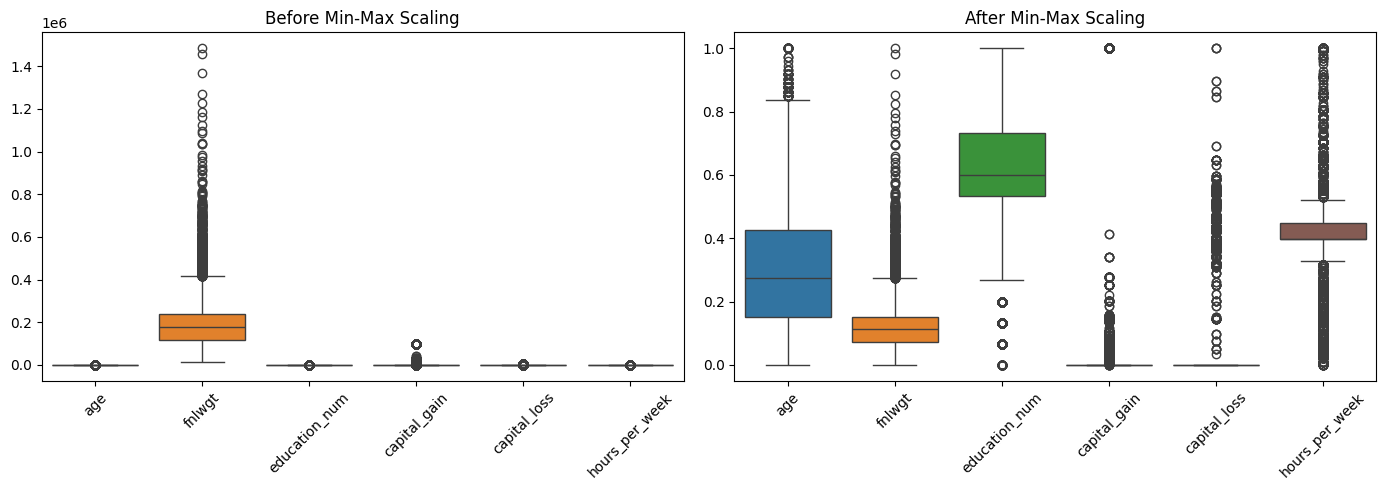

In [ ]:
# Boxplot comparison

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.boxplot(
    data=df[numerical_columns_for_scaling],
    ax=axes[0]
)

axes[0].set_title(
    "Before Min-Max Scaling"
)

axes[0].tick_params(
    axis='x',
    rotation=45
)

sns.boxplot(
    data=df_minmax_scaled[
        numerical_columns_for_scaling
    ],
    ax=axes[1]
)

axes[1].set_title(
    "After Min-Max Scaling"
)

axes[1].tick_params(
    axis='x',
    rotation=45
)

plt.tight_layout()
plt.show()

6.11 When Should We Use StandardScaler?

StandardScaler is generally preferable when:

  features have different scales

  data contains some outliers

  the algorithm benefits from centered features

  we don't need a fixed range

Common examples:

Logistic Regression

Linear Regression

SVM

KNN

K-Means

PCA

Regularized Regression


6.12 When Should We Use MinMaxScaler?

Min-Max Scaling is useful when:

  a fixed range is desirable

  features need to be constrained between 0 and 1

  algorithms benefit from normalized input

  the dataset doesn't contain problematic extreme outliers

For example:

Neural Networks

Distance-based algorithms

Certain optimization problems

In [ ]:
# Min-Max Scaling is particularly sensitive to outliers.

### Q: "What is the difference between StandardScaler and MinMaxScaler?"
answer:

"StandardScaler transforms features to approximately zero mean and unit variance, while MinMaxScaler maps values to a defined range, commonly 0 to 1. StandardScaler is often preferred when centered features are useful and a fixed range isn't required, whereas MinMaxScaler is useful when bounded feature values are desirable. However, MinMaxScaler is highly sensitive to extreme minimum and maximum values, so I would examine outliers before selecting it."

# Step 7 — Categorical Feature Analysis

In [ ]:
# ============================================
#  Categorical Feature Analysis
# ============================================

categorical_columns = df.select_dtypes(
    include='object'
).columns.tolist()

print("Categorical Features:")
print(categorical_columns)

Categorical Features:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


In [ ]:
# Number of unique categories in each categorical feature

categorical_cardinality = (
    df[categorical_columns]
    .nunique()
    .sort_values()
)

categorical_cardinality

,0
sex,2
income,2
race,5
relationship,6
marital_status,7
workclass,8
occupation,14
education,16
native_country,41


In [ ]:
# Categorical feature summary

categorical_summary = pd.DataFrame({
    'Feature': categorical_columns,
    'Unique Categories': [
        df[col].nunique()
        for col in categorical_columns
    ],
    'Missing Values': [
        df[col].isnull().sum()
        for col in categorical_columns
    ]
})

categorical_summary = (
    categorical_summary
    .sort_values(
        by='Unique Categories'
    )
    .reset_index(drop=True)
)

categorical_summary

,Feature,Unique Categories,Missing Values
0,sex,2,0
1,income,2,0
2,race,5,0
3,relationship,6,0
4,marital_status,7,0
5,workclass,8,0
6,occupation,14,0
7,education,16,0
8,native_country,41,0


In [ ]:
# Low-cardinality categorical features (< 5 categories)

low_cardinality_features = [
    col for col in categorical_columns
    if df[col].nunique() < 5
]

# Higher-cardinality categorical features (> 5 categories)

high_cardinality_features = [
    col for col in categorical_columns
    if df[col].nunique() > 5
]

print("Low-Cardinality Features (< 5):")
print(low_cardinality_features)

print("\nHigher-Cardinality Features (> 5):")
print(high_cardinality_features)

Low-Cardinality Features (< 5):
['sex', 'income']

Higher-Cardinality Features (> 5):
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'native_country']


In [ ]:
# Features with exactly 5 categories

exactly_five_categories = [
    col for col in categorical_columns
    if df[col].nunique() == 5
]

print("Features with exactly 5 categories:")
print(exactly_five_categories)

Features with exactly 5 categories:
['race']


In [ ]:
# Display categories for each categorical feature

for col in categorical_columns:
    print(f"\n{'=' * 50}")
    print(f"{col}")
    print(f"{'=' * 50}")
    print(df[col].unique())


workclass
[' State-gov' ' Self-emp-not-inc' ' Private' ' Federal-gov' ' Local-gov'
 ' Self-emp-inc' ' Without-pay' ' Never-worked']

education
[' Bachelors' ' HS-grad' ' 11th' ' Masters' ' 9th' ' Some-college'
 ' Assoc-acdm' ' Assoc-voc' ' 7th-8th' ' Doctorate' ' Prof-school'
 ' 5th-6th' ' 10th' ' 1st-4th' ' Preschool' ' 12th']

marital_status
[' Never-married' ' Married-civ-spouse' ' Divorced'
 ' Married-spouse-absent' ' Separated' ' Married-AF-spouse' ' Widowed']

occupation
[' Adm-clerical' ' Exec-managerial' ' Handlers-cleaners' ' Prof-specialty'
 ' Other-service' ' Sales' ' Craft-repair' ' Transport-moving'
 ' Farming-fishing' ' Machine-op-inspct' ' Tech-support'
 ' Protective-serv' ' Armed-Forces' ' Priv-house-serv']

relationship
[' Not-in-family' ' Husband' ' Wife' ' Own-child' ' Unmarried'
 ' Other-relative']

race
[' White' ' Black' ' Asian-Pac-Islander' ' Amer-Indian-Eskimo' ' Other']

sex
[' Male' ' Female']

native_country
[' United-States' ' Cuba' ' Jamaica' ' India' ' M

In [ ]:
# Frequency distribution for categorical variables

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())


workclass
workclass
Private             24532
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

education
education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           333
1st-4th           168
Preschool          51
Name: count, dtype: int64

marital_status
marital_status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64

occupation
occupation
Prof-specialty       5983
Craft-repair         40

In [ ]:
# Percentage distribution of categories

for col in categorical_columns:

    print(f"\n{'=' * 50}")
    print(col)
    print(f"{'=' * 50}")

    percentages = (
        df[col]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    print(percentages)


workclass
workclass
Private             75.34
Self-emp-not-inc     7.80
Local-gov            6.43
State-gov            3.99
Self-emp-inc         3.43
Federal-gov          2.95
Without-pay          0.04
Never-worked         0.02
Name: proportion, dtype: float64

education
education
HS-grad         32.25
Some-college    22.39
Bachelors       16.45
Masters          5.29
Assoc-voc        4.24
11th             3.61
Assoc-acdm       3.28
10th             2.87
7th-8th          1.98
Prof-school      1.77
9th              1.58
12th             1.33
Doctorate        1.27
5th-6th          1.02
1st-4th          0.52
Preschool        0.16
Name: proportion, dtype: float64

marital_status
marital_status
Married-civ-spouse       45.99
Never-married            32.81
Divorced                 13.65
Separated                 3.15
Widowed                   3.05
Married-spouse-absent     1.28
Married-AF-spouse         0.07
Name: proportion, dtype: float64

occupation
occupation
Prof-specialty       18.37
C

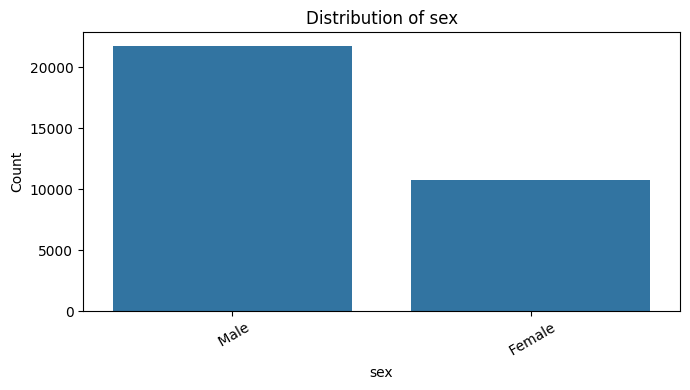

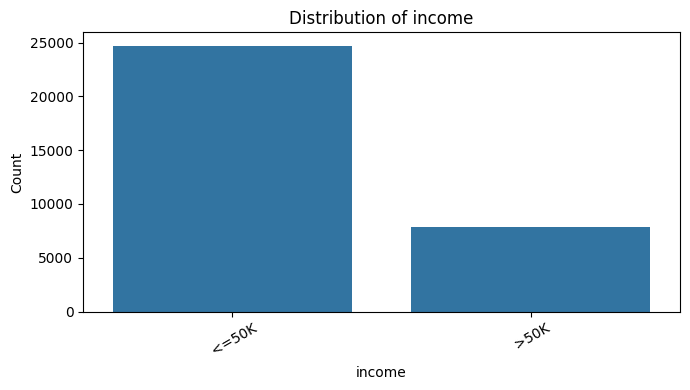

In [ ]:
# Visualize low-cardinality categorical features

for col in low_cardinality_features:

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=col
    )

    plt.title(
        f"Distribution of {col}"
    )

    plt.xlabel(col)
    plt.ylabel("Count")

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [ ]:
# Top categories for higher-cardinality features

for col in high_cardinality_features:

    print(f"\nTop categories for: {col}")

    display(
        df[col]
        .value_counts()
        .head(10)
        .to_frame('Count')
    )


Top categories for: workclass


,Count
workclass,
Private,24532
Self-emp-not-inc,2541
Local-gov,2093
State-gov,1298
Self-emp-inc,1116
Federal-gov,960
Without-pay,14
Never-worked,7



Top categories for: education


,Count
education,
HS-grad,10501
Some-college,7291
Bachelors,5355
Masters,1723
Assoc-voc,1382
11th,1175
Assoc-acdm,1067
10th,933
7th-8th,646



Top categories for: marital_status


,Count
marital_status,
Married-civ-spouse,14976
Never-married,10683
Divorced,4443
Separated,1025
Widowed,993
Married-spouse-absent,418
Married-AF-spouse,23


... (2 outputs left out)


Top categories for: relationship


,Count
relationship,
Husband,13193
Not-in-family,8305
Own-child,5068
Unmarried,3446
Wife,1568
Other-relative,981



Top categories for: native_country


,Count
native_country,
United-States,29753
Mexico,643
Philippines,198
Germany,137
Canada,121
Puerto-Rico,114
El-Salvador,106
India,100
Cuba,95


In [ ]:
# Final categorical cardinality analysis

categorical_analysis = pd.DataFrame({
    'Feature': categorical_columns,
    'Unique Categories': [
        df[col].nunique()
        for col in categorical_columns
    ]
})

categorical_analysis['Cardinality Group'] = (
    categorical_analysis['Unique Categories']
    .apply(
        lambda x:
        '< 5'
        if x < 5
        else '= 5'
        if x == 5
        else '> 5'
    )
)

categorical_analysis.sort_values(
    by='Unique Categories'
).reset_index(drop=True)

,Feature,Unique Categories,Cardinality Group
0,sex,2,< 5
1,income,2,< 5
2,race,5,= 5
3,relationship,6,> 5
4,marital_status,7,> 5
5,workclass,8,> 5
6,occupation,14,> 5
7,education,16,> 5
8,native_country,41,> 5


"How did you decide how to encode categorical variables?"

answer:

"I first analyzed categorical cardinality and the nature of each variable. For low-cardinality categorical features, I used One-Hot Encoding to avoid introducing artificial ordinal relationships. For higher-cardinality variables, I considered the dimensionality impact of one-hot encoding and the limitations of assigning arbitrary integer labels. The encoding strategy was therefore based on both cardinality and the semantic nature of the variable rather than cardinality alone."

# Step 8 — Categorical Encoding

In [ ]:
# ============================================
#  Categorical Encoding
# ============================================

# Separate features and target

X = df.drop(columns=['income'])
y = df['income']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (32561, 15)
Target Shape: (32561,)


In [ ]:
# Check the target

y.value_counts()

,count
income,
<=50K,24720
>50K,7841


In [ ]:
# Identify categorical features

categorical_features = X.select_dtypes(
    include='object'
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

Categorical Features:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


In [ ]:
# Identify numerical features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

Numerical Features:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'capital_gain_log']


In [ ]:
# Low-cardinality features: fewer than 5 categories

low_cardinality_features = [
    col for col in categorical_features
    if X[col].nunique() < 5
]

# Higher-cardinality features: more than 5 categories

high_cardinality_features = [
    col for col in categorical_features
    if X[col].nunique() > 5
]

# Exactly 5 categories

exactly_five_features = [
    col for col in categorical_features
    if X[col].nunique() == 5
]

print("Low Cardinality (<5):")
print(low_cardinality_features)

print("\nExactly 5:")
print(exactly_five_features)

print("\nHigh Cardinality (>5):")
print(high_cardinality_features)

Low Cardinality (<5):
['sex']

Exactly 5:
['race']

High Cardinality (>5):
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'native_country']


In [ ]:
# Apply One-Hot Encoding to low-cardinality features

X_encoded = pd.get_dummies(
    X,
    columns=low_cardinality_features,
    drop_first=False,
    dtype=int
)

X_encoded.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,capital_gain_log,sex_ Female,sex_ Male
0,39.0,State-gov,77516.0,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,2174.0,0.0,40.0,United-States,7.684784,0,1
1,50.0,Self-emp-not-inc,83311.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,0.0,0.0,13.0,United-States,0.000000,0,1
2,38.0,Private,215646.0,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,0.0,0.0,40.0,United-States,0.000000,0,1
3,53.0,Private,234721.0,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,0.0,0.0,40.0,United-States,0.000000,0,1
4,28.0,Private,338409.0,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,0.0,0.0,40.0,Cuba,0.000000,1,0


In [ ]:
# Columns after One-Hot Encoding

new_columns = [
    col for col in X_encoded.columns
    if col not in X.columns
]

print("New One-Hot Encoded Columns:")
print(new_columns)

New One-Hot Encoded Columns:
['sex_ Female', 'sex_ Male']


In [ ]:
print("Original Shape:", X.shape)
print("After One-Hot Encoding:", X_encoded.shape)

Original Shape: (32561, 15)
After One-Hot Encoding: (32561, 16)


In [ ]:
# Inspect one encoded feature

if low_cardinality_features:

    example_feature = low_cardinality_features[0]

    print("Original Feature:")
    print(X[example_feature].value_counts())

    print("\nEncoded Columns:")
    encoded_example_columns = [
        col for col in X_encoded.columns
        if col.startswith(example_feature + "_")
    ]

    print(encoded_example_columns)

    display(
        X_encoded[encoded_example_columns].head(10)
    )

Original Feature:
sex
Male      21790
Female    10771
Name: count, dtype: int64

Encoded Columns:
['sex_ Female', 'sex_ Male']


,sex_ Female,sex_ Male
0,0,1
1,0,1
2,0,1
3,0,1
4,1,0
5,1,0
6,1,0
7,0,1
8,1,0
9,0,1


In [ ]:
print("Higher-cardinality features:")
print(high_cardinality_features)

Higher-cardinality features:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'native_country']


In [ ]:
if 'occupation' in high_cardinality_features:
    label_feature = 'occupation'
else:
    label_feature = high_cardinality_features[0]

print("Selected Label Encoding Feature:", label_feature)

Selected Label Encoding Feature: occupation


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

X_encoded[label_feature + '_label'] = (
    label_encoder.fit_transform(
        X[label_feature]
    )
)

In [ ]:
# Display Label Encoding mapping

label_mapping = dict(
    zip(
        label_encoder.classes_,
        label_encoder.transform(
            label_encoder.classes_
        )
    )
)

label_mapping

{' Adm-clerical': np.int64(0),
 ' Armed-Forces': np.int64(1),
 ' Craft-repair': np.int64(2),
 ' Exec-managerial': np.int64(3),
 ' Farming-fishing': np.int64(4),
 ' Handlers-cleaners': np.int64(5),
 ' Machine-op-inspct': np.int64(6),
 ' Other-service': np.int64(7),
 ' Priv-house-serv': np.int64(8),
 ' Prof-specialty': np.int64(9),
 ' Protective-serv': np.int64(10),
 ' Sales': np.int64(11),
 ' Tech-support': np.int64(12),
 ' Transport-moving': np.int64(13)}

In [ ]:
X_encoded = X_encoded.drop(
    columns=[label_feature]
)

In [ ]:
X_encoded.dtypes.value_counts()

,count
float64,7
object,6
int64,3


What About Other Higher-Cardinality Variables?

This is where professional preprocessing differs from blindly applying Label Encoding.

We should not automatically label encode every categorical column with >5 categories.

Instead, options include:

Option 1 — One-Hot Encoding

Good when cardinality is manageable.

Option 2 — Frequency Encoding

Replace each category with its frequency.

Option 3 — Target Encoding

Useful in some supervised learning settings, but must be performed carefully to avoid target leakage.

Option 4 — Ordinal Encoding

Appropriate when categories have a genuine order.

Option 5 — Feature Grouping

Rare categories can sometimes be combined into "Other".

### Discuss One-Hot vs Label Encoding

| Aspect                      | One-Hot Encoding        | Label Encoding                           |
| --------------------------- | ----------------------- | ---------------------------------------- |
| Output                      | Multiple binary columns | Single integer column                    |
| Creates artificial ordering | ❌                       | ⚠️ Potentially                           |
| Number of columns           | Increases               | No increase                              |
| Memory usage                | Can be high             | Low                                      |
| Low cardinality             | Excellent               | Can be problematic for nominal variables |
| High cardinality            | Can create many columns | Compact                                  |
| Interpretability            | High                    | Moderate                                 |
| Suitable for ordinal data   | Not necessary           | ✅                                        |
| Suitable for nominal data   | ✅                       | ⚠️ Depends on model/usage                |


In [ ]:
# Check remaining categorical columns

remaining_object_columns = X_encoded.select_dtypes(
    include='object'
).columns.tolist()

print(
    "Remaining categorical columns:",
    remaining_object_columns
)

Remaining categorical columns: ['workclass', 'education', 'marital_status', 'relationship', 'race', 'native_country']


In [ ]:
# Check data types after encoding

X_encoded.dtypes.value_counts()

,count
float64,7
object,6
int64,3


In [ ]:
print("Original Feature Shape:", X.shape)
print("Encoded Feature Shape:", X_encoded.shape)

Original Feature Shape: (32561, 15)
Encoded Feature Shape: (32561, 16)


In [ ]:
# Verify missing values

X_encoded.isnull().sum().sum()

np.int64(0)

"Why didn't you Label Encode every categorical variable?"

answer:

"Label Encoding converts categories into integers, which can unintentionally introduce an ordinal relationship between nominal categories. I therefore used One-Hot Encoding for low-cardinality nominal variables and treated higher-cardinality variables separately, considering dimensionality and the semantic nature of each feature. Label Encoding is more naturally suited to ordinal categories where the numerical ordering has genuine meaning."

# Step 9 — Ordinal Encoding & Feature Engineering

In [ ]:
# ============================================
#  Ordinal Encoding & Feature Engineering
# ============================================

# Examine education categories

education_categories = (
    df['education']
    .value_counts()
)

education_categories

,count
education,
HS-grad,10501
Some-college,7291
Bachelors,5355
Masters,1723
Assoc-voc,1382
11th,1175
Assoc-acdm,1067
10th,933
7th-8th,646


In [ ]:
# Compare education with education-num

education_mapping = (
    df[['education', 'education_num']]
    .drop_duplicates()
    .sort_values('education_num')
)

education_mapping

,education,education_num
224,Preschool,1.0
160,1st-4th,2.0
56,5th-6th,3.0
15,7th-8th,4.0
6,9th,5.0
77,10th,6.0
3,11th,7.0
415,12th,8.0
2,HS-grad,9.0
10,Some-college,10.0


In [ ]:
# Unique education categories

df['education'].unique()

array([' Bachelors', ' HS-grad', ' 11th', ' Masters', ' 9th',
       ' Some-college', ' Assoc-acdm', ' Assoc-voc', ' 7th-8th',
       ' Doctorate', ' Prof-school', ' 5th-6th', ' 10th', ' 1st-4th',
       ' Preschool', ' 12th'], dtype=object)

In [ ]:
# Explicit education hierarchy

education_order = [
    'Preschool',
    '1st-4th',
    '5th-6th',
    '7th-8th',
    '9th',
    '10th',
    '11th',
    '12th',
    'HS-grad',
    'Some-college',
    'Assoc-voc',
    'Assoc-acdm',
    'Bachelors',
    'Masters',
    'Prof-school',
    'Doctorate'
]

In [ ]:
# Create ordinal mapping

education_mapping_dict = {
    education: rank
    for rank, education in enumerate(
        education_order
    )
}

education_mapping_dict

{'Preschool': 0,
 '1st-4th': 1,
 '5th-6th': 2,
 '7th-8th': 3,
 '9th': 4,
 '10th': 5,
 '11th': 6,
 '12th': 7,
 'HS-grad': 8,
 'Some-college': 9,
 'Assoc-voc': 10,
 'Assoc-acdm': 11,
 'Bachelors': 12,
 'Masters': 13,
 'Prof-school': 14,
 'Doctorate': 15}

In [ ]:
# # Apply ordinal encoding

# df['education_ordinal'] = (
#     df['education']
#     .map(education_mapping_dict)
# )

In [ ]:
# Clean education values before ordinal encoding
df['education'] = (
    df['education']
    .astype(str)
    .str.strip()
)

# Apply ordinal encoding
df['education_ordinal'] = (
    df['education']
    .map(education_mapping_dict)
)

In [ ]:
# Verify ordinal encoding

df[
    ['education', 'education_ordinal']
].drop_duplicates().sort_values(
    'education_ordinal'
)

,education,education_ordinal
224,Preschool,0
160,1st-4th,1
56,5th-6th,2
15,7th-8th,3
6,9th,4
77,10th,5
3,11th,6
415,12th,7
2,HS-grad,8
10,Some-college,9


In [ ]:
# Remove redundant demonstration feature

df.drop(
    columns=['education_ordinal'],
    inplace=True
)

In [ ]:
# ============================================
# Feature Engineering 1:
# Work Hours Category
# ============================================

def categorize_work_hours(hours):

    if hours < 30:
        return 'Part-Time'

    elif hours < 40:
        return 'Near Full-Time'

    elif hours == 40:
        return 'Full-Time'

    else:
        return 'Overtime'


df['work_hours_category'] = (
    df['hours_per_week']
    .apply(categorize_work_hours)
)

In [ ]:
# Check engineered feature

df[
    [
        'hours_per_week',
        'work_hours_category'
    ]
].head(10)

,hours_per_week,work_hours_category
0,40.0,Full-Time
1,13.0,Part-Time
2,40.0,Full-Time
3,40.0,Full-Time
4,40.0,Full-Time
5,40.0,Full-Time
6,16.0,Part-Time
7,45.0,Overtime
8,50.0,Overtime
9,40.0,Full-Time


In [ ]:
# Frequency of work-hour categories

df['work_hours_category'].value_counts()

,count
work_hours_category,
Full-Time,15217
Overtime,9581
Part-Time,4096
Near Full-Time,3667


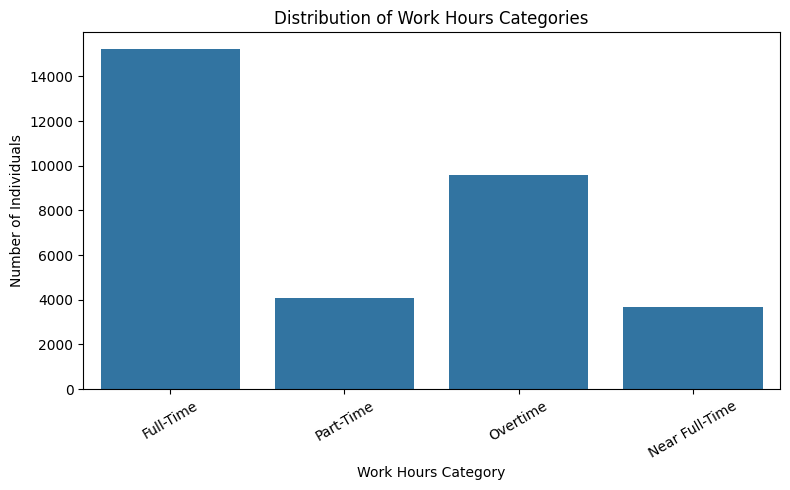

In [ ]:
# Visualize work-hour categories

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='work_hours_category'
)

plt.title(
    "Distribution of Work Hours Categories"
)

plt.xlabel("Work Hours Category")
plt.ylabel("Number of Individuals")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# Feature Engineering 2:
# Net Capital
# ============================================

df['net_capital'] = (
    df['capital_gain']
    - df['capital_loss']
)

In [ ]:
# Check net capital

df[
    [
        'capital_gain',
        'capital_loss',
        'net_capital'
    ]
].head(10)

,capital_gain,capital_loss,net_capital
0,2174.0,0.0,2174.0
1,0.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,0.0,0.0
4,0.0,0.0,0.0
5,0.0,0.0,0.0
6,0.0,0.0,0.0
7,0.0,0.0,0.0
8,14084.0,0.0,14084.0
9,5178.0,0.0,5178.0


In [ ]:
# Summary statistics

df['net_capital'].describe()

,net_capital
count,32561.000000
mean,990.345014
std,7408.986951
min,-4356.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,99999.000000


In [ ]:
# Skewness

df['net_capital'].skew()

np.float64(11.871933918984418)

In [ ]:
# Work hours category vs income

pd.crosstab(
    df['work_hours_category'],
    df['income'],
    normalize='index'
).round(3)

income,<=50K,>50K
work_hours_category,,
Full-Time,0.787,0.213
Near Full-Time,0.872,0.128
Overtime,0.598,0.402
Part-Time,0.934,0.066


In [ ]:
# Net capital statistics by income class

df.groupby('income')['net_capital'].agg(
    ['mean', 'median', 'min', 'max']
)

,mean,median,min,max
income,,,,
<=50K,95.609547,0.0,-4356.0,41310.0
>50K,3811.140926,0.0,-3683.0,99999.0


In [ ]:
# Age Group

df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=[
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        '56-65',
        '65+'
    ]
)

In [ ]:
df[
    ['age', 'age_group']
].head(10)

,age,age_group
0,39.0,36-45
1,50.0,46-55
2,38.0,36-45
3,53.0,46-55
4,28.0,26-35
5,37.0,36-45
6,49.0,46-55
7,52.0,46-55
8,31.0,26-35
9,42.0,36-45


In [ ]:
# Display newly engineered features

df[
    [
        'hours_per_week',
        'work_hours_category',
        'capital_gain',
        'capital_loss',
        'net_capital'
    ]
].head(10)

,hours_per_week,work_hours_category,capital_gain,capital_loss,net_capital
0,40.0,Full-Time,2174.0,0.0,2174.0
1,13.0,Part-Time,0.0,0.0,0.0
2,40.0,Full-Time,0.0,0.0,0.0
3,40.0,Full-Time,0.0,0.0,0.0
4,40.0,Full-Time,0.0,0.0,0.0
5,40.0,Full-Time,0.0,0.0,0.0
6,16.0,Part-Time,0.0,0.0,0.0
7,45.0,Overtime,0.0,0.0,0.0
8,50.0,Overtime,14084.0,0.0,14084.0
9,40.0,Full-Time,5178.0,0.0,5178.0


In [ ]:
print("Dataset Shape After Feature Engineering:")
print(df.shape)

Dataset Shape After Feature Engineering:
(32561, 19)


### Feature Engineering Summary
We created:

| New Feature           | Technique                 | Business Meaning          |
| --------------------- | ------------------------- | ------------------------- |
| `work_hours_category` | Binning                   | Employment/work intensity |
| `net_capital`         | Arithmetic transformation | Net financial position    |
| `age_group`           | Binning                   | Life-stage representation |


"What feature engineering did you perform?"

answer:

"I created meaningful domain-driven features rather than arbitrary mathematical combinations. I transformed weekly working hours into employment-intensity categories such as Part-Time, Full-Time, and Overtime, and created a net capital feature by combining capital gains and losses. These features provide more interpretable representations of work patterns and financial position that may help explain income differences."

# Step 10 — Advanced Feature Selection & Anomaly Detection

#### What is Isolation Forest?

Isolation Forest is an unsupervised anomaly-detection algorithm.

The basic idea is:

An unusual observation is easier to isolate from the rest of the data.

For example, in the Adult Income dataset, a person with extremely unusual combinations of:

age

education number

capital gain

capital loss

hours per week

may be flagged as potentially anomalous.

Why use it?

It can help us identify:

unusual records

extreme observations

potential data-quality problems

observations that deserve further investigation

#### Select Numerical Features
Isolation Forest works conveniently with numerical data.

First identify the numerical columns:

In [ ]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

numerical_columns

['age',
 'fnlwgt',
 'education_num',
 'capital_gain',
 'capital_loss',
 'hours_per_week',
 'capital_gain_log',
 'net_capital']

If income has already been converted into a numerical target, exclude it because we don't want the target to influence anomaly detection.

In [ ]:
numerical_features = [
    col for col in numerical_columns
    if col != 'income'
]

numerical_features

['age',
 'fnlwgt',
 'education_num',
 'capital_gain',
 'capital_loss',
 'hours_per_week',
 'capital_gain_log',
 'net_capital']

#### Prepare Data for Isolation Forest
Isolation Forest cannot work directly with missing values, so verify that our numerical features contain no missing values:

In [ ]:
df[numerical_features].isnull().sum()

,0
age,0
fnlwgt,0
education_num,0
capital_gain,0
capital_loss,0
hours_per_week,0
capital_gain_log,0
net_capital,0


In [ ]:
# Now create the input:

X_anomaly = df[numerical_features].copy()

X_anomaly.head()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,capital_gain_log,net_capital
0,39.0,77516.0,13.0,2174.0,0.0,40.0,7.684784,2174.0
1,50.0,83311.0,13.0,0.0,0.0,13.0,0.000000,0.0
2,38.0,215646.0,9.0,0.0,0.0,40.0,0.000000,0.0
3,53.0,234721.0,7.0,0.0,0.0,40.0,0.000000,0.0
4,28.0,338409.0,13.0,0.0,0.0,40.0,0.000000,0.0


In [ ]:
# Train Isolation Forest

from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

df['anomaly_prediction'] = iso_forest.fit_predict(X_anomaly)

#### Interpretation
Isolation Forest returns:

1 → Normal observation

-1 → Potential anomaly

Let's inspect:

In [ ]:
df['anomaly_prediction'].value_counts()

,count
anomaly_prediction,
1,30933
-1,1628


In [ ]:
# Calculate Anomaly Percentage

anomaly_count = (df['anomaly_prediction'] == -1).sum()
normal_count = (df['anomaly_prediction'] == 1).sum()

total_count = len(df)

anomaly_percentage = (anomaly_count / total_count) * 100

print("Total observations:", total_count)
print("Normal observations:", normal_count)
print("Potential anomalies:", anomaly_count)
print("Anomaly percentage:", round(anomaly_percentage, 2), "%")

Total observations: 32561
Normal observations: 30933
Potential anomalies: 1628
Anomaly percentage: 5.0 %


Because we specified:

contamination=0.05

we are asking the model to treat approximately 5% of observations as potential anomalies.

Important

This does not mean that exactly 5% of the records are objectively incorrect.

It is a modeling assumption controlling how aggressively the algorithm flags observations.

Inspect Potential Anomalies

Let's look at the flagged records:

In [ ]:
anomalies = df[df['anomaly_prediction'] == -1]

anomalies.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,capital_gain_log,work_hours_category,net_capital,age_group,anomaly_prediction
8,31.0,Private,45781.0,Masters,14.0,Never-married,Prof-specialty,Not-in-family,White,Female,14084.0,0.0,50.0,United-States,>50K,9.552866,Overtime,14084.0,26-35,-1
52,47.0,Private,51835.0,Prof-school,15.0,Married-civ-spouse,Prof-specialty,Wife,White,Female,0.0,1902.0,60.0,Honduras,>50K,0.000000,Overtime,-1902.0,46-55,-1
84,44.0,Private,343591.0,HS-grad,9.0,Divorced,Craft-repair,Not-in-family,White,Female,14344.0,0.0,40.0,United-States,>50K,9.571157,Full-Time,14344.0,36-45,-1
96,48.0,Self-emp-not-inc,191277.0,Doctorate,16.0,Married-civ-spouse,Prof-specialty,Husband,White,Male,0.0,1902.0,60.0,United-States,>50K,0.000000,Overtime,-1902.0,46-55,-1
101,44.0,Private,198282.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,15024.0,0.0,60.0,United-States,>50K,9.617471,Overtime,15024.0,36-45,-1


In [ ]:
# And inspect their numerical characteristics:

anomalies[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age,1628.0,48.050369,14.506126,17.0,38.00,47.000000,58.000000,9.000000e+01
fnlwgt,1628.0,203056.619165,127353.043377,19899.0,115483.25,177328.000000,274695.000000,1.033222e+06
education_num,1628.0,11.504914,3.360071,1.0,9.00,13.000000,14.000000,1.600000e+01
capital_gain,1628.0,17103.550983,28217.959131,0.0,0.00,7688.000000,15024.000000,9.999900e+04
capital_loss,1628.0,586.681204,980.927676,0.0,0.00,0.000000,1633.000000,4.356000e+03
hours_per_week,1628.0,45.833538,16.683943,1.0,40.00,45.000000,55.000000,9.900000e+01
capital_gain_log,1628.0,6.832139,4.361890,0.0,0.00,8.947546,9.617471,1.151293e+01
net_capital,1628.0,16516.869779,28588.396862,-4356.0,-1633.00,7688.000000,15024.000000,9.999900e+04


In [ ]:
# Compare them with normal observations:

normal_data = df[df['anomaly_prediction'] == 1]

normal_data[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age,30933.0,38.083309,13.409647,17.0,27.0,37.0,47.0,9.000000e+01
fnlwgt,30933.0,189079.533702,104231.909781,12285.0,117944.0,178421.0,236323.0,1.484705e+06
education_num,30933.0,10.005722,2.502204,1.0,9.0,10.0,12.0,1.600000e+01
capital_gain,30933.0,234.207578,1141.103310,0.0,0.0,0.0,0.0,1.052000e+04
capital_loss,30933.0,61.021660,326.335976,0.0,0.0,0.0,0.0,2.339000e+03
hours_per_week,30933.0,40.153461,12.009529,1.0,40.0,40.0,45.0,9.900000e+01
capital_gain_log,30933.0,0.413709,1.811714,0.0,0.0,0.0,0.0,9.261129e+00
net_capital,30933.0,173.185918,1198.831234,-2339.0,0.0,0.0,0.0,1.052000e+04


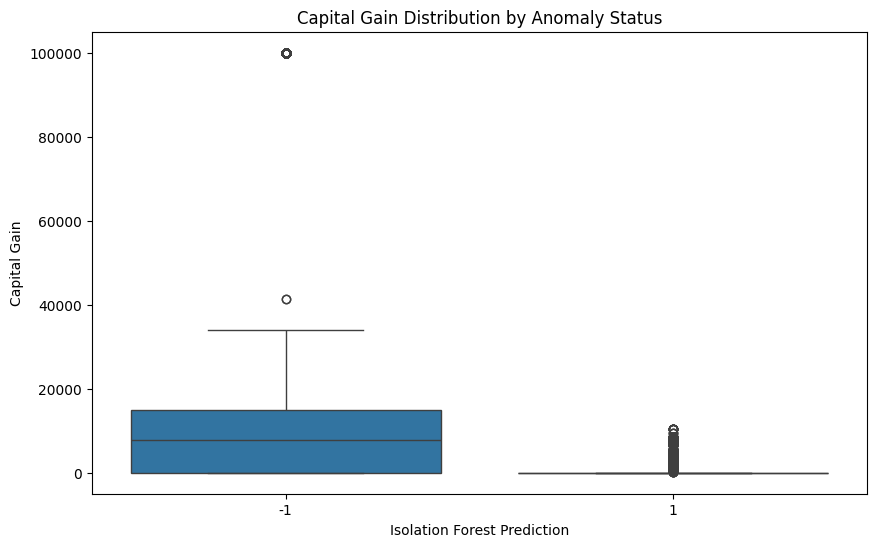

In [ ]:
# Visualize Anomalies
# For example, visualize capital_gain:

plt.figure(figsize=(10, 6))

sns.boxplot(
    x=df['anomaly_prediction'],
    y=df['capital_gain']
)

plt.title("Capital Gain Distribution by Anomaly Status")
plt.xlabel("Isolation Forest Prediction")
plt.ylabel("Capital Gain")

plt.show()

#### Should We Remove the Anomalies?

Recommended approach

Detect → Flag → Investigate → Decide

rather than:

Detect → Delete

### What is PPS?

Predictive Power Score (PPS) measures how well one variable can predict another variable.

The score generally ranges from:

0 → No predictive power

1 → Perfect predictive power

Unlike simple correlation, PPS can capture non-linear relationships and can work with categorical as well as numerical variables.

#### Why PPS is Useful

Correlation mainly measures certain forms of numerical association.

For example:

X ↔ Y

PPS asks a slightly different question:

How well can X predict Y?

This makes PPS useful for:

-- feature selection

-- identifying potentially useful predictors

-- discovering non-linear relationships

-- understanding relationships between categorical and numerical variables

In [ ]:
# Install ppscore

!pip install ppscore

  Preparing metadata (setup.py) ... done
  Created wheel for ppscore: filename=ppscore-1.3.1-py2.py3-none-any.whl size=13226 sha256=67a261cd93b2a98e064733e82066eecdc82c8a5cab3307210fe95426be26bbbe
  Stored in directory: /root/.cache/pip/wheels/b4/95/1f/bfb3b7b3845232909c01caa738277f86d0148164d3a617ad42
Successfully built ppscore


In [ ]:
# Then import:

import ppscore as pps

In [ ]:
# Calculate the PPS Matrix

pps_matrix = pps.matrix(df)

pps_matrix.head()

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=4.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=4.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=4.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=4.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=4.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklea

,x,y,ppscore,case,is_valid_score,metric,baseline_score,model_score,model
0,age,age,1.000000,predict_itself,True,None,0.00000,1.000000,None
1,age,workclass,0.000000,classification,True,weighted F1,0.65501,0.654813,DecisionTreeClassifier()
2,age,fnlwgt,0.000000,regression,True,mean absolute error,75872.18620,77535.141544,DecisionTreeRegressor()
3,age,education,0.052315,classification,True,weighted F1,0.20120,0.242989,DecisionTreeClassifier()
4,age,education_num,0.000000,regression,True,mean absolute error,1.85300,1.898306,DecisionTreeRegressor()


The resulting dataframe contains information such as:

x

y

ppscore

model information

baseline score

In [ ]:
# Find Features Predicting Income

income_pps = (
    pps_matrix[pps_matrix['y'] == 'income']
    [['x', 'y', 'ppscore']]
    .sort_values('ppscore', ascending=False)
)

income_pps

,x,y,ppscore
294,income,income,1.000000
354,net_capital,income,0.400876
314,capital_gain_log,income,0.297578
214,capital_gain,income,0.297123
94,education_num,income,0.243135
74,education,income,0.243135
394,anomaly_prediction,income,0.223951
234,capital_loss,income,0.141755
34,workclass,income,0.094056
134,occupation,income,0.092410


This gives us a ranked view of the predictive relationship with the target.

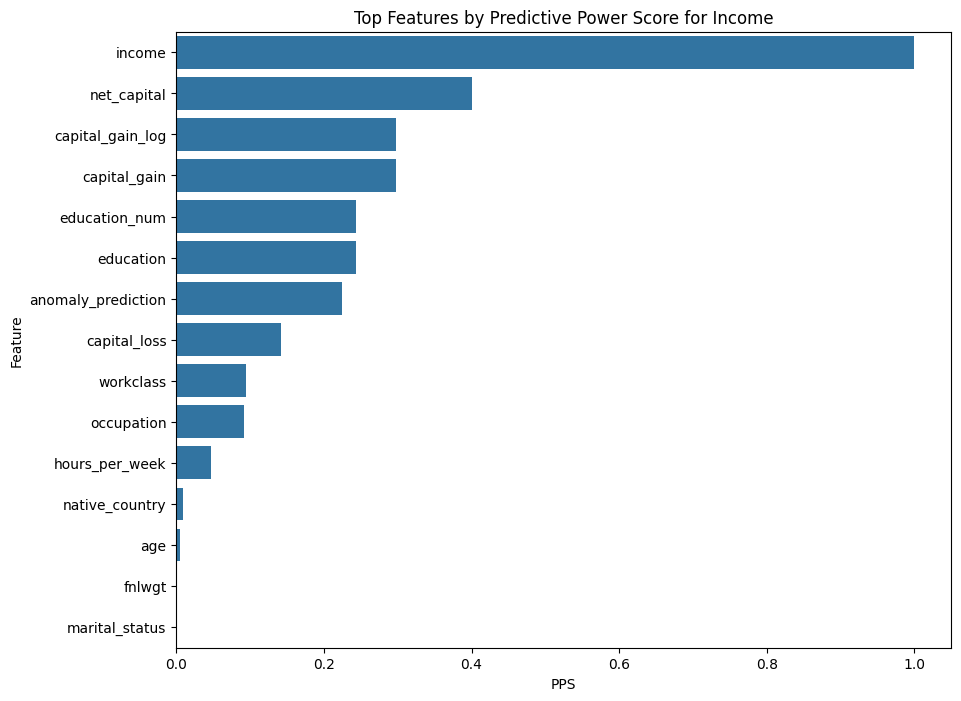

In [ ]:
# Visualize PPS

plt.figure(figsize=(10, 8))

sns.barplot(
    data=income_pps.head(15),
    x='ppscore',
    y='x'
)

plt.title("Top Features by Predictive Power Score for Income")
plt.xlabel("PPS")
plt.ylabel("Feature")

plt.show()

# This helps us visually identify potentially useful predictors.

### PPS vs Correlation

| Correlation                          | PPS                                             |
| ------------------------------------ | ----------------------------------------------- |
| Measures statistical association     | Measures predictive capability                  |
| Mainly numerical variables           | Can handle categorical and numerical variables  |
| Often focused on linear relationship | Can capture non-linear predictive relationships |
| Symmetric concept                    | Directional: X → Y                              |
| Range generally -1 to +1             | Range 0 to 1                                    |
| Useful for relationship analysis     | Useful for predictive feature analysis          |


Example

Suppose:

Age → Income

and:

Income → Age

PPS treats these as different predictive directions.

That is one reason PPS can provide information that ordinary correlation does not.

#### Important Feature Selection Caution

Don't simply say:

"The highest PPS features are selected and everything else is deleted."

That would be an oversimplification.

Feature selection should also consider:

-- domain meaning

-- redundancy

-- multicollinearity

-- model performance

-- data leakage

-- interpretability

-- train/test separation

Most importantly, the target must not leak into the predictors.

For example, if a feature is derived directly from income, it should not be used to predict income.

### Isolation Forest

Isolation Forest was applied to the numerical variables to identify potentially anomalous observations. The algorithm assigned each observation a prediction of 1 for normal observations and -1 for potential anomalies. The detected observations were investigated rather than automatically removed because unusual values may represent valid real-world records.

### PPS Analysis

Predictive Power Score was used to evaluate the predictive relationship between individual features and the income target. PPS provides directional predictive information and can capture relationships that may not be adequately represented by simple correlation analysis. Features with higher PPS values can be considered potentially more useful for prediction, subject to further validation and leakage checks.

### Don't fit preprocessing on the entire dataset before model training.
For a production ML pipeline:

Raw Dataset

     ↓

Train/Test Split

     ↓

Fit preprocessing on TRAIN

     ↓

Transform TRAIN

     ↓

Transform TEST using same fitted objects

     ↓
Feature Selection

     ↓
Model Training

     ↓
Evaluation


This prevents data leakage.

# Step 11 — Build the Final Cleaned & ML-Ready Dataset

In [ ]:
# First — Create a Final Working Copy

df_final = df.copy()

print("Final working dataset shape:", df_final.shape)

Final working dataset shape: (32561, 20)


In [ ]:
# Check Missing Values

missing_values = (
    df_final.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_values[missing_values > 0]

,0


In [ ]:
# Check Remaining ? Values

question_mark_count = (
    df_final.astype(str)
    .apply(lambda col: col.str.strip().eq('?').sum())
    .sort_values(ascending=False)
)

question_mark_count[question_mark_count > 0]

,0


In [ ]:
# Check Duplicate Records

duplicate_count = df_final.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 24


In [ ]:
df_final = df_final.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df_final.shape)

Shape after removing duplicates: (32537, 20)


Why remove duplicates?

Duplicate rows can cause:

--> biased statistics

--> over-representation of certain observations

--> misleading model performance

However, duplicates should be removed only when they represent true duplicate records, not legitimate repeated observations.

In [ ]:
# Check Data Types

df_final.dtypes

,0
age,float64
workclass,object
fnlwgt,float64
education,object
education_num,float64
marital_status,object
occupation,object
relationship,object
race,object
sex,object


In [ ]:
# Separate them:

categorical_columns = df_final.select_dtypes(
    include='object'
).columns.tolist()

numerical_columns = df_final.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income', 'work_hours_category']

Numerical columns:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'capital_gain_log', 'net_capital', 'anomaly_prediction']


In [ ]:
# Separate Features and Target

X = df_final.drop(columns=['income'])
y = df_final['income']

In [ ]:
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (32537, 19)
Target shape: (32537,)


In [ ]:
y.value_counts()

,count
income,
<=50K,24698
>50K,7839


Encode the Target Variable

Machine-learning models generally need the target represented numerically.

In [ ]:
# Use an explicit mapping:

y = y.astype(str).str.strip()

target_mapping = {
    '<=50K': 0,
    '>50K': 1
}

y_encoded = y.map(target_mapping)

In [ ]:
print(y_encoded.value_counts())

income
0    24698
1     7839
Name: count, dtype: int64


In [ ]:
print("Missing target values:", y_encoded.isnull().sum())

Missing target values: 0


In [ ]:
# Identify Remaining Categorical Features

categorical_features = X.select_dtypes(
    include='object'
).columns.tolist()

categorical_features

['workclass',
 'education',
 'marital_status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'native_country',
 'work_hours_category']

In [ ]:
# And their cardinalities:

X[categorical_features].nunique().sort_values()

,0
sex,2
work_hours_category,4
race,5
relationship,6
marital_status,7
workclass,8
occupation,14
education,16
native_country,41


In [ ]:
# One-Hot Encode Categorical Variables

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=False,
    dtype=int
)

In [ ]:
print("Encoded feature shape:", X_encoded.shape)

Encoded feature shape: (32537, 113)


In [ ]:
X_encoded.head()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,capital_gain_log,net_capital,age_group,anomaly_prediction,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Never-worked,workclass_ Private,workclass_ Self-emp-inc,workclass_ Self-emp-not-inc,workclass_ State-gov,workclass_ Without-pay,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital_status_ Divorced,marital_status_ Married-AF-spouse,marital_status_ Married-civ-spouse,marital_status_ Married-spouse-absent,marital_status_ Never-married,marital_status_ Separated,marital_status_ Widowed,occupation_ Adm-clerical,occupation_ Armed-Forces,occupation_ Craft-repair,occupation_ Exec-managerial,occupation_ Farming-fishing,occupation_ Handlers-cleaners,occupation_ Machine-op-inspct,occupation_ Other-service,occupation_ Priv-house-serv,occupation_ Prof-specialty,occupation_ Protective-serv,occupation_ Sales,occupation_ Tech-support,occupation_ Transport-moving,relationship_ Husband,relationship_ Not-in-family,relationship_ Other-relative,relationship_ Own-child,relationship_ Unmarried,relationship_ Wife,race_ Amer-Indian-Eskimo,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,native_country_ Cambodia,native_country_ Canada,native_country_ China,native_country_ Columbia,native_country_ Cuba,native_country_ Dominican-Republic,native_country_ Ecuador,native_country_ El-Salvador,native_country_ England,native_country_ France,native_country_ Germany,native_country_ Greece,native_country_ Guatemala,native_country_ Haiti,native_country_ Holand-Netherlands,native_country_ Honduras,native_country_ Hong,native_country_ Hungary,native_country_ India,native_country_ Iran,native_country_ Ireland,native_country_ Italy,native_country_ Jamaica,native_country_ Japan,native_country_ Laos,native_country_ Mexico,native_country_ Nicaragua,native_country_ Outlying-US(Guam-USVI-etc),native_country_ Peru,native_country_ Philippines,native_country_ Poland,native_country_ Portugal,native_country_ Puerto-Rico,native_country_ Scotland,native_country_ South,native_country_ Taiwan,native_country_ Thailand,native_country_ Trinadad&Tobago,native_country_ United-States,native_country_ Vietnam,native_country_ Yugoslavia,work_hours_category_Full-Time,work_hours_category_Near Full-Time,work_hours_category_Overtime,work_hours_category_Part-Time
0,39.0,77516.0,13.0,2174.0,0.0,40.0,7.684784,2174.0,36-45,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
1,50.0,83311.0,13.0,0.0,0.0,13.0,0.000000,0.0,46-55,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
2,38.0,215646.0,9.0,0.0,0.0,40.0,0.000000,0.0,36-45,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
3,53.0,234721.0,7.0,0.0,0.0,40.0,0.000000,0.0,46-55,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
4,28.0,338409.0,13.0,0.0,0.0,40.0,0.000000,0.0,26-35,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [ ]:
# Verify No Object Columns Remain

remaining_object_columns = X_encoded.select_dtypes(
    include='object'
).columns.tolist()

remaining_object_columns

[]

In [ ]:
print(
    "Number of categorical columns remaining:",
    len(remaining_object_columns)
)

Number of categorical columns remaining: 0


Handle Boolean Columns

Depending on the pandas version and how the data was encoded, get_dummies() may produce Boolean columns.

In [ ]:
X_encoded.dtypes.value_counts()

,count
int64,104
float64,8
category,1


In [ ]:
# If Boolean columns exist:

boolean_columns = X_encoded.select_dtypes(
    include='bool'
).columns

X_encoded[boolean_columns] = X_encoded[boolean_columns].astype(int)

In [ ]:
X_encoded.dtypes.value_counts()

,count
int64,104
float64,8
category,1


Combine X and y

Now create the final ML dataset:

In [ ]:
df_ml = X_encoded.copy()

df_ml['income'] = y_encoded

print("Final ML dataset shape:", df_ml.shape)

Final ML dataset shape: (32537, 114)


In [ ]:
df_ml.head()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,capital_gain_log,net_capital,age_group,anomaly_prediction,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Never-worked,workclass_ Private,workclass_ Self-emp-inc,workclass_ Self-emp-not-inc,workclass_ State-gov,workclass_ Without-pay,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital_status_ Divorced,marital_status_ Married-AF-spouse,marital_status_ Married-civ-spouse,marital_status_ Married-spouse-absent,marital_status_ Never-married,marital_status_ Separated,marital_status_ Widowed,occupation_ Adm-clerical,occupation_ Armed-Forces,occupation_ Craft-repair,occupation_ Exec-managerial,occupation_ Farming-fishing,occupation_ Handlers-cleaners,occupation_ Machine-op-inspct,occupation_ Other-service,occupation_ Priv-house-serv,occupation_ Prof-specialty,occupation_ Protective-serv,occupation_ Sales,occupation_ Tech-support,occupation_ Transport-moving,relationship_ Husband,relationship_ Not-in-family,relationship_ Other-relative,relationship_ Own-child,relationship_ Unmarried,relationship_ Wife,race_ Amer-Indian-Eskimo,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,native_country_ Cambodia,native_country_ Canada,native_country_ China,native_country_ Columbia,native_country_ Cuba,native_country_ Dominican-Republic,native_country_ Ecuador,native_country_ El-Salvador,native_country_ England,native_country_ France,native_country_ Germany,native_country_ Greece,native_country_ Guatemala,native_country_ Haiti,native_country_ Holand-Netherlands,native_country_ Honduras,native_country_ Hong,native_country_ Hungary,native_country_ India,native_country_ Iran,native_country_ Ireland,native_country_ Italy,native_country_ Jamaica,native_country_ Japan,native_country_ Laos,native_country_ Mexico,native_country_ Nicaragua,native_country_ Outlying-US(Guam-USVI-etc),native_country_ Peru,native_country_ Philippines,native_country_ Poland,native_country_ Portugal,native_country_ Puerto-Rico,native_country_ Scotland,native_country_ South,native_country_ Taiwan,native_country_ Thailand,native_country_ Trinadad&Tobago,native_country_ United-States,native_country_ Vietnam,native_country_ Yugoslavia,work_hours_category_Full-Time,work_hours_category_Near Full-Time,work_hours_category_Overtime,work_hours_category_Part-Time,income
0,39.0,77516.0,13.0,2174.0,0.0,40.0,7.684784,2174.0,36-45,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
1,50.0,83311.0,13.0,0.0,0.0,13.0,0.000000,0.0,46-55,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
2,38.0,215646.0,9.0,0.0,0.0,40.0,0.000000,0.0,36-45,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
3,53.0,234721.0,7.0,0.0,0.0,40.0,0.000000,0.0,46-55,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
4,28.0,338409.0,13.0,0.0,0.0,40.0,0.000000,0.0,26-35,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


In [ ]:
# Check Final Dataset Information

df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32537 entries, 0 to 32536
Columns: 114 entries, age to income
dtypes: category(1), float64(8), int64(105)
memory usage: 28.1 MB


In [ ]:
# Final Feature Summary

final_summary = pd.DataFrame({
    'Feature': df_ml.columns,
    'Data_Type': df_ml.dtypes.astype(str).values,
    'Missing_Values': df_ml.isnull().sum().values,
    'Unique_Values': df_ml.nunique().values
})

final_summary.head(20)

,Feature,Data_Type,Missing_Values,Unique_Values
0,age,float64,0,73
1,fnlwgt,float64,0,21648
2,education_num,float64,0,16
3,capital_gain,float64,0,119
4,capital_loss,float64,0,92
5,hours_per_week,float64,0,94
6,capital_gain_log,float64,0,119
7,net_capital,float64,0,210
8,age_group,category,0,6
9,anomaly_prediction,int64,0,2


In [ ]:
# Save the Final Dataset

df_ml.to_csv(
    'adult_income_ml_ready.csv',
    index=False
)

In [ ]:
# Verify:

import os

print(
    "File exists:",
    os.path.exists('adult_income_ml_ready.csv')
)

File exists: True


In [ ]:
# Final Validation Block

print("=" * 60)
print("FINAL ML DATASET VALIDATION")
print("=" * 60)

print("Shape:", df_ml.shape)

print(
    "Missing values:",
    df_ml.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    df_ml.duplicated().sum()
)

print(
    "Non-numeric columns:",
    len(
        df_ml.select_dtypes(
            exclude=np.number
        ).columns
    )
)

print(
    "Target unique values:",
    df_ml['income'].unique()
)

print("=" * 60)

FINAL ML DATASET VALIDATION
Shape: (32537, 114)
Missing values: 0
Duplicate rows: 0
Non-numeric columns: 1
Target unique values: [0 1]


### Conclusion

The Adult Income dataset was systematically preprocessed to make it suitable for machine-learning analysis. Missing-value indicators were identified and handled using appropriate imputation techniques. Numerical features were analyzed and scaled using StandardScaler and MinMaxScaler, while the highly skewed capital-gain feature was transformed using a logarithmic transformation. Categorical variables were analyzed according to their cardinality and encoded appropriately. Ordinal information in education was recognized, and meaningful features such as work_hours_category and net_capital were engineered. Isolation Forest was used to identify potentially anomalous observations, while Predictive Power Score was used to examine feature-level predictive relationships with income. Finally, the processed dataset was validated to ensure that missing values and non-numeric features were appropriately handled, producing a structured dataset suitable for machine-learning applications.